# Load Dependencies

In [1]:
## Load dependencies
import numpy as np
import pandas as pd
import mne
import yasa ## main package, built upon mne
import re ## regular expression operations
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta, timezone

# Load Files

In [2]:
## File Paths
## EDF files
EEG_DIR = Path('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/sleep_edf')
## .csv files
HYPNO_DIR = Path('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/scored_csv')

In [3]:
# ## Parsing subject_id, sleep_condition, and verifying uploads worked
# def parse_filename(path: Path):
#     """DXA_001_normal.edf converts to ('DXA_001', 'normal'); DXA_001_9TIB.csv converts to ('DXA_001', '9TIB')"""
#     subject_id, condition = path.stem.rsplit("_", 1)
#     return subject_id.strip().upper(), condition.strip()

# def build_manifest(eeg_dir, hypn_dir):
#     eeg = pd.DataFrame(
#         [(*parse_filename(p), p) for p in Path(eeg_dir).rglob("*.edf")],
#         columns=["subject_id", "condition", "edf_path"])
#     hyp = pd.DataFrame(
#         [(*parse_filename(p), p) for p in Path(hypn_dir).rglob("*.csv")],
#         columns=["subject_id", "condition", "hyp_path"])
#     manifest = eeg.merge(hyp, on=["subject_id", "condition"], how="outer", indicator=True)
#     return manifest.sort_values(["subject_id", "condition"]).reset_index(drop=True)

# manifest = build_manifest(eeg_dir, hypno_dir)

# ## Check for any standalone EEG or hypnogram files lacking their counterpart
# print(manifest["_merge"].value_counts())
# print("=========")
# print(manifest[manifest["_merge"] != "both"])
# ## Duplicate keys would silently double-count nights
# assert not manifest.duplicated(["subject_id", "condition"]).any(), "Duplicate subject/condition"

# manifest = manifest[manifest["_merge"] == "both"].drop(columns="_merge")

## Establish file settings and parameters

In [4]:
## CELL 2 | Settings

EEG_CH = "EEG4"                       # EEG channel; EEG1 = EMG, EEG2 = REOG, EEG3 = LEOG are not used
EPOCH_SEC = 30

# Hypnogram column names after header cleanup (lower case, spaces -> underscores)
EPOCH_COL     = "epoch_#"
STAGE_COL     = "stage_final"
SECONDARY_COL = "secondaryautostage"
CLOCK_COL     = "clocktime"           # clock time at the start of each epoch (HH:MM:SS)
ELAPSED_COL   = "elapsedtime(sec)"    # seconds on the Study Editor timeline, at the start of each epoch

NRH_CODE = 14                         # non-REM hypertonia
INVALID_CODE = 9                      # outside the begin/end study markers (and bad signal)

# Study Editor -> EDF time offset:  EDF time = ElapsedTime(sec) + offset
SP_TO_EDF_OFFSET_SEC = 10.0
OFFSET_OVERRIDES = {}                 # exceptions by hypnogram file stem, e.g. {"DXA_010_9TIB": 12.0}

GAP_ANNOTATION = "BAD_gap"

## Convert Sleep Profiler scoring system to 5-stage system (AASM & YASA)

In [5]:
## CELL 3 | Sleep Profiler codes -> YASA's five stages
STAGE_MAP = {
    0: "WAKE", 1: "N1", 2: "N2", 3: "N3",
    4: "N2",     # L2 (light N2)
    5: "REM",
    6: "UNS",    # NOS: sleep not otherwise specified
    9: "UNS",    # INVALID
    14: "N2",    # NRH: normally replaced by SecondaryAutoStage in load_hypno(); N2 is only the fallback
    33: "N3",    # atypical N3
    55: "REM",   # RSWA: REM without atonia
}
STAGE_INT = {"WAKE": 0, "N1": 1, "N2": 2, "N3": 3, "REM": 4, "UNS": -2}   # YASA's integer stage codes (-2 = unscored)

## Build File Manifest

In [6]:
## CELL 4 | File-name parsing and manifest builder
def parse_filename(path: Path):
    """DXA_001_normal.edf -> ('DXA_001', 'normal'); DXA_001_9TIB.csv -> ('DXA_001', '9TIB')"""
    subject_id, condition = path.stem.rsplit("_", 1)
    return subject_id.strip().upper(), condition.strip()

def build_manifest(eeg_dir, hypno_dir):
    eeg = pd.DataFrame([(*parse_filename(p), p) for p in Path(eeg_dir).rglob("*.edf")],
                       columns=["subject_id", "condition", "edf_path"])
    hyp = pd.DataFrame([(*parse_filename(p), p) for p in Path(hypno_dir).rglob("*.csv")],
                       columns=["subject_id", "condition", "hyp_path"])
    m = eeg.merge(hyp, on=["subject_id", "condition"], how="outer", indicator=True)
    return m.sort_values(["subject_id", "condition"]).reset_index(drop=True)

In [7]:
## CELL 5 | Build the manifest and check the pairing
manifest = build_manifest(EEG_DIR, HYPNO_DIR)
print(manifest["_merge"].value_counts())
unpaired = manifest[manifest["_merge"] != "both"]
if len(unpaired):
    print("Files without a partner:")
    display(unpaired)
assert not manifest.duplicated(["subject_id", "condition"]).any(), "Duplicate subject/condition"

manifest = manifest[manifest["_merge"] == "both"].drop(columns="_merge").reset_index(drop=True)
print(f"{len(manifest)} EEG/hypnogram pairs; {manifest['subject_id'].nunique()} participants")
manifest.head()

_merge
both          20
left_only      0
right_only     0
Name: count, dtype: int64
20 EEG/hypnogram pairs; 10 participants


,subject_id,condition,edf_path,hyp_path
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...


# Load Hypnogram files, define functions

In [8]:
## CELL 6 | Read a hypnogram and map it to YASA's five stages (NRH rule included)
def read_hypno_df(csv_path):
    df = pd.read_csv(csv_path, encoding="utf-8-sig")
    df.columns = df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
    return df.sort_values(EPOCH_COL).reset_index(drop=True)

def load_hypno(csv_path, window=None):
    """Returns (yasa.Hypnogram, resolved Sleep Profiler codes). window=(i0, i1) keeps only those rows (B to C)."""
    df = read_hypno_df(csv_path)
    missing = [c for c in (EPOCH_COL, STAGE_COL, SECONDARY_COL) if c not in df.columns]
    if missing:
        raise KeyError(f"{missing} not found. Columns present: {df.columns.tolist()}")
    if not (np.diff(df[EPOCH_COL].to_numpy()) == 1).all():
        raise ValueError("epoch_# is not contiguous (gaps or duplicates)")

    # NRH epochs take the secondary auto stage; a missing secondary value stays NRH, which falls back to N2
    resolved = df[STAGE_COL].where(df[STAGE_COL] != NRH_CODE, df[SECONDARY_COL])
    resolved = resolved.fillna(NRH_CODE).astype(int)

    stages = resolved.map(STAGE_MAP)
    if stages.isna().any():
        raise ValueError(f"Unmapped stage codes: {sorted(resolved[stages.isna()].unique())}")

    if window is not None:
        i0, i1 = window
        stages, resolved = stages.iloc[i0:i1 + 1], resolved.iloc[i0:i1 + 1]
    return yasa.Hypnogram(stages.to_numpy(), freq="30s"), resolved

In [9]:
## CELL 7 | NRH audit: which stages do the NRH (14) epochs take from SecondaryAutoStage? (whole files)
rows = []
for r in manifest.itertuples():
    d = read_hypno_df(r.hyp_path)
    nrh = d[STAGE_COL] == NRH_CODE
    sec = d.loc[nrh, SECONDARY_COL].map(STAGE_MAP).fillna("missing")
    rows.append({"subject_id": r.subject_id, "condition": r.condition,
                 "n_nrh": int(nrh.sum()), **sec.value_counts().to_dict()})
nrh_audit = pd.DataFrame(rows).fillna(0)
display(nrh_audit)

,subject_id,condition,n_nrh,N2,N3
0,DXA_001,9TIB,0,0.0,0.0
1,DXA_001,normal,0,0.0,0.0
2,DXA_002,9TIB,8,7.0,1.0
3,DXA_002,normal,12,0.0,12.0
4,DXA_003,9TIB,120,10.0,110.0
5,DXA_003,normal,0,0.0,0.0
6,DXA_004,9TIB,0,0.0,0.0
7,DXA_004,normal,21,13.0,8.0
8,DXA_005,9TIB,0,0.0,0.0
9,DXA_005,normal,0,0.0,0.0


## Timing and trim functions

In [10]:
## CELL 8 | Open an EDF (EEG channel only, nothing loaded yet) and a display helper
def open_edf(edf_path):
    """Lazy read: keeps only EEG_CH; n_times is available without loading the samples."""
    raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
    if EEG_CH not in raw.ch_names:
        raise KeyError(f"{EEG_CH} not in EDF channels: {raw.ch_names}")
    raw.pick([EEG_CH])
    return raw

def show(df):
    """Display a table without the EDF_trim column (it holds Raw objects, which break the table preview)."""
    display(df.drop(columns=[c for c in ["EDF_trim"] if c in df.columns]))

In [11]:
## CELL 9 | Time helpers: clock formatting, the Study Editor -> EDF offset, epoch start times, gap finder
def to_clock_sec(series):
    """HH:MM:SS strings -> seconds, unwrapped across midnight."""
    s = pd.to_timedelta(series.astype(str).str.strip()).dt.total_seconds().to_numpy()
    return s + 86400 * np.cumsum(np.r_[0, np.diff(s) < 0])

def fmt_clock(sec):
    return str(timedelta(seconds=float(sec) % 86400)).split(".")[0]

def hms(sec):
    s = int(round(sec))
    return f"{s // 3600}:{(s % 3600) // 60:02d}:{s % 60:02d}"

def edf_offset(csv_path):
    return OFFSET_OVERRIDES.get(Path(csv_path).stem, SP_TO_EDF_OFFSET_SEC)

def epoch_starts_edf(csv_path):
    """Start of each epoch on the EDF time axis (s) = ElapsedTime(sec) + this file's offset."""
    df = read_hypno_df(csv_path)
    return df[ELAPSED_COL].to_numpy(dtype=float) + edf_offset(csv_path)

def find_gaps(el_win, tmin):
    """Unscored gaps: wherever consecutive epoch starts are more than 30 s apart.
    Returns (start, end) in seconds from the start of the cropped EEG."""
    steps = np.diff(el_win)
    k = np.where(steps > EPOCH_SEC + 0.5)[0]
    return [(float(el_win[i] + EPOCH_SEC - tmin), float(el_win[i + 1] - tmin)) for i in k]

In [12]:
## CELL 10 | The sleep window B-C from the hypnogram (first to last epoch whose Stage final is not 9)
def hypno_timing(csv_path):
    df = read_hypno_df(csv_path)
    off = edf_offset(csv_path)
    stage = df[STAGE_COL].to_numpy()
    el_raw = df[ELAPSED_COL].to_numpy(dtype=float)     # Study Editor time at the start of each epoch
    el = el_raw + off                                  # the same epoch starts on the EDF time axis
    clk = to_clock_sec(df[CLOCK_COL])                  # epoch starts, clock seconds
    valid = stage != INVALID_CODE
    if not valid.any():
        raise ValueError("No valid (non-9) epochs in hypnogram")
    i0 = int(np.argmax(valid))
    i1 = len(valid) - 1 - int(np.argmax(valid[::-1]))
    excess = np.diff(el[i0:i1 + 1]) - EPOCH_SEC
    return {
        "i0": i0, "i1": i1, "offset": off,
        "epoch_first": int(df[EPOCH_COL].iloc[i0]), "epoch_last": int(df[EPOCH_COL].iloc[i1]),
        "stage_first": int(stage[i0]), "stage_last": int(stage[i1]),
        "n_invalid_inside": int((~valid[i0:i1 + 1]).sum()),
        "n_win_epochs": i1 - i0 + 1,
        "n_gaps": int((excess > 0.5).sum()),
        "gap_total_sec": float(excess[excess > 0.5].sum()),
        "rec_start_se": clk[0] - el_raw[0],            # clock at Study Editor second 0 (epoch1_clock - elapsed_epoch1_sec)
        "rec_start": clk[0] - el[0],                   # clock at EDF second 0 (header start to enter in EDFBrowser)
        "epoch1_clock": clk[0], "elapsed0": el_raw[0], "epoch1_edf": el[0],
        "b_elapsed": el_raw[i0], "c_elapsed": el_raw[i1] + EPOCH_SEC,   # B and C on the Study Editor axis
        "tmin": el[i0], "tmax": el[i1] + EPOCH_SEC,                     # B and C on the EDF axis (the crop times)
        "clk_start": clk[i0], "clk_end": clk[i1] + EPOCH_SEC,           # B and C read from ClockTime
        "hypno_end_on_edf": el[-1] + EPOCH_SEC,        # end of the file's last row (any stage), EDF axis
    }

In [13]:
## CELL 11 | Crop a COPY of an opened EDF to B-C (used by the trim report)
def trim_edf_to_sleep_window(raw, tm):
    sf = raw.info["sfreq"]
    edf_len = raw.n_times / sf
    tmin, tmax = tm["tmin"], tm["tmax"]
    if tmin < -1 or tmax > edf_len + 1:
        raise ValueError(f"Sleep window [{tmin:.1f}, {tmax:.1f}] s extends outside EDF (0-{edf_len:.1f} s)")
    tmin, tmax = max(tmin, 0.0), min(tmax, edf_len)
    return raw.copy().crop(tmin=tmin, tmax=tmax - 1 / sf, include_tmax=True)

# Trim Report

In [14]:
## CELL 12 | Trim alignment report (all nights)
rows, failed = [], []
for r in manifest.itertuples():
    try:
        raw = open_edf(r.edf_path)                       # lazy: no data loaded
        sf = raw.info["sfreq"]
        tm = hypno_timing(r.hyp_path)
        edf_total = raw.n_times / sf

        try:
            edf_dur = trim_edf_to_sleep_window(raw, tm).n_times / sf
            trim_error = ""
        except ValueError as e:
            edf_dur, trim_error = np.nan, str(e)

        edf_start_clk = tm["rec_start"] + tm["tmin"]     # B, EDF-axis derived
        edf_end_clk   = tm["rec_start"] + tm["tmax"]     # C, EDF-axis derived
        hyp_dur_epochs = tm["n_win_epochs"] * EPOCH_SEC

        row = {
            "subject_id": r.subject_id, "condition": r.condition,
            "epoch1_clock": fmt_clock(tm["epoch1_clock"]), "elapsed_epoch1_sec": tm["elapsed0"],
            "rec_start_clock": fmt_clock(tm["rec_start_se"]),     # = epoch1_clock - elapsed_epoch1_sec (Study Editor time 0)
            "sp_to_edf_offset_sec": tm["offset"],
            "epoch1_edf_sec": tm["epoch1_edf"],                   # epoch 1 on the EDF axis (elapsed_epoch1_sec + offset)
            "edf_zero_clock": fmt_clock(tm["rec_start"]),         # clock at EDF second 0 (header start for EDFBrowser)
            "sleep_start_epoch": tm["epoch_first"], "sleep_end_epoch": tm["epoch_last"],
            "stage_at_start": tm["stage_first"], "stage_at_end": tm["stage_last"],
            "n_invalid_inside": tm["n_invalid_inside"],
            "b_elapsed_sec": tm["b_elapsed"], "c_elapsed_sec": tm["c_elapsed"],
            "hyp_start_clock": fmt_clock(tm["clk_start"]), "hyp_end_clock": fmt_clock(tm["clk_end"]),
            "edf_start_clock": fmt_clock(edf_start_clk),  "edf_end_clock": fmt_clock(edf_end_clk),
            "start_diff_sec": round(edf_start_clk - tm["clk_start"], 2),
            "end_diff_sec": round(edf_end_clk - tm["clk_end"], 2),
            "n_gaps": tm["n_gaps"], "gap_total_sec": round(tm["gap_total_sec"], 1),
            "hyp_dur_min": round(hyp_dur_epochs / 60, 2),
            "hyp_dur_clock_min": round((tm["clk_end"] - tm["clk_start"]) / 60, 2),
            "edf_dur_min": round(edf_dur / 60, 2),
            "dur_diff_sec": round(edf_dur - hyp_dur_epochs, 2),
            "dur_diff_ex_gaps_sec": round(edf_dur - hyp_dur_epochs - tm["gap_total_sec"], 2),
            "edf_total_min": round(edf_total / 60, 2),
            "trim_start_sec": round(tm["tmin"], 1),                       # removed from the start of the EDF
            "trim_end_sec": round(edf_total - tm["tmax"], 1),             # removed from the end (negative = EDF too short)
            "edf_minus_hypno_end_sec": round(edf_total - tm["hypno_end_on_edf"], 1),
            "trim_error": trim_error,
        }
        row["checks_ok"] = bool(abs(row["dur_diff_ex_gaps_sec"]) <= 1 and tm["stage_last"] == 0 and not trim_error)
        row["clock_ok"] = bool(abs(row["start_diff_sec"]) <= 1 and abs(row["end_diff_sec"]) <= 1)
        rows.append(row)
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"{len(rows)} nights checked, {len(failed)} failed")
for f in failed[:10]:
    print(f)

if rows:
    trim_report = pd.DataFrame(rows)
    print(f"{int(trim_report['checks_ok'].sum())} of {len(trim_report)} pass checks_ok; "
          f"{int(trim_report['clock_ok'].sum())} of {len(trim_report)} pass clock_ok")
    display(trim_report)

20 nights checked, 0 failed
20 of 20 pass checks_ok; 18 of 20 pass clock_ok


,subject_id,condition,epoch1_clock,elapsed_epoch1_sec,rec_start_clock,sp_to_edf_offset_sec,epoch1_edf_sec,edf_zero_clock,sleep_start_epoch,sleep_end_epoch,...,edf_dur_min,dur_diff_sec,dur_diff_ex_gaps_sec,edf_total_min,trim_start_sec,trim_end_sec,edf_minus_hypno_end_sec,trim_error,checks_ok,clock_ok
0,DXA_001,9TIB,23:08:18,15.0,23:08:03,10.0,25.0,23:07:53,1,1095,...,547.50,0.0,0.0,548.48,25.0,34.0,34.0,,True,True
1,DXA_001,normal,22:41:54,16.0,22:41:38,10.0,26.0,22:41:28,1,1118,...,559.00,0.0,0.0,559.55,26.0,7.0,7.0,,True,True
2,DXA_002,9TIB,1:56:49,15.0,1:56:34,10.0,25.0,1:56:24,3,978,...,488.00,0.0,0.0,544.58,85.0,3310.0,10.0,,True,True
3,DXA_002,normal,2:17:07,15.0,2:16:52,10.0,25.0,2:16:42,22,846,...,412.50,0.0,0.0,433.28,655.0,592.0,22.0,,True,True
4,DXA_003,9TIB,1:21:28,49.0,1:20:39,10.0,59.0,1:20:29,1,812,...,406.00,0.0,0.0,407.10,59.0,7.0,7.0,,True,True
5,DXA_003,normal,2:11:59,15.0,2:11:44,10.0,25.0,2:11:34,2,597,...,298.00,0.0,0.0,300.38,55.0,88.0,28.0,,True,True
6,DXA_004,9TIB,23:30:46,15.0,23:30:31,10.0,25.0,23:30:21,1,1119,...,559.50,0.0,0.0,560.87,25.0,57.0,57.0,,True,True
7,DXA_004,normal,1:11:58,16.0,1:11:42,10.0,26.0,1:11:32,1,697,...,348.50,0.0,0.0,349.40,26.0,28.0,28.0,,True,True
8,DXA_005,9TIB,23:29:57,15.0,23:29:42,10.0,25.0,23:29:32,1,1083,...,541.50,0.0,0.0,542.27,25.0,21.0,21.0,,True,True
9,DXA_005,normal,0:43:44,15.0,0:43:29,10.0,25.0,0:43:19,1,928,...,464.60,36.0,0.0,465.37,25.0,21.0,21.0,,True,False


In [15]:
## CELL 13 | Name the reason a night fails (adds a column to trim_report)
def fail_reasons(row):
    out = []
    if row["trim_error"]:                     out.append("EDF does not cover the sleep window")
    if abs(row["dur_diff_ex_gaps_sec"]) > 1: out.append("EEG length != epochs x 30 s + gaps")
    if row["stage_at_end"] != 0:              out.append("last valid epoch is not wake")
    if not row["clock_ok"]:                   out.append("ClockTime disagrees with ElapsedTime(sec)")
    return "; ".join(out)

trim_report["fail_reasons"] = trim_report.apply(fail_reasons, axis=1)
display(trim_report.loc[trim_report["fail_reasons"] != "",
                        ["subject_id", "condition", "checks_ok", "clock_ok", "fail_reasons"]])

,subject_id,condition,checks_ok,clock_ok,fail_reasons
9,DXA_005,normal,True,False,ClockTime disagrees with ElapsedTime(sec)
12,DXA_010,9TIB,True,False,ClockTime disagrees with ElapsedTime(sec)


DXA_001 / 9TIB   (sampling rate 256.0 Hz, offset 10.0 s)
EDF length: 548.48 min
Epoch 1: elapsed 15 s -> EDF 25 s
B on Study Editor axis: 15 s | C: 32865 s
crop on EDF axis: tmin = 25 s (B + offset), tmax = 32875 s (C + offset)
Trimmed from start: 0.42 min | from end: 0.57 min
Cropped EEG: 32850.0 s | epochs x 30 s: 32850 s | documented gaps: 0.0 s   <- first = second + third
Gaps (start, end in s from start of cropped EEG): []
Stage at B: 0 | at C: 0 (C expected 0 = wake) | invalid (9) epochs inside: 0
Around B: [0, 0, 0] (3 before | 3 inside)
Around C: [5, 5, 0] (3 inside | 3 after)


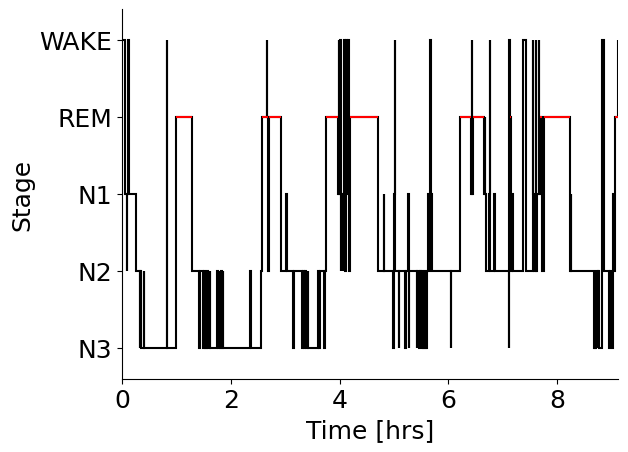

In [16]:
## CELL 14 | Spot check one night (nothing is written)
SPOT = (None, None)    # e.g. ("DXA_010", "9TIB"); None = first row of manifest

row = manifest.iloc[0] if SPOT[0] is None else \
      manifest[(manifest["subject_id"] == SPOT[0]) & (manifest["condition"] == SPOT[1])].iloc[0]

tm = hypno_timing(row["hyp_path"])
raw = open_edf(row["edf_path"])
sf = raw.info["sfreq"]
edf_total = raw.n_times / sf
trimmed = trim_edf_to_sleep_window(raw, tm)
hyp, codes = load_hypno(row["hyp_path"], window=(tm["i0"], tm["i1"]))
gaps = find_gaps(epoch_starts_edf(row["hyp_path"])[tm["i0"]:tm["i1"] + 1], max(tm["tmin"], 0.0))

print(f"{row['subject_id']} / {row['condition']}   (sampling rate {sf} Hz, offset {tm['offset']} s)")
print(f"EDF length: {edf_total / 60:.2f} min")
print(f"Epoch 1: elapsed {tm['elapsed0']:.0f} s -> EDF {tm['epoch1_edf']:.0f} s")
print(f"B on Study Editor axis: {tm['b_elapsed']:.0f} s | C: {tm['c_elapsed']:.0f} s")
print(f"crop on EDF axis: tmin = {tm['tmin']:.0f} s (B + offset), tmax = {tm['tmax']:.0f} s (C + offset)")
print(f"Trimmed from start: {max(tm['tmin'], 0) / 60:.2f} min | from end: {(edf_total - tm['tmax']) / 60:.2f} min")
print(f"Cropped EEG: {trimmed.n_times / sf:.1f} s | epochs x 30 s: {len(hyp) * EPOCH_SEC} s | "
      f"documented gaps: {sum(e - s for s, e in gaps):.1f} s   <- first = second + third")
print(f"Gaps (start, end in s from start of cropped EEG): {gaps}")
print(f"Stage at B: {tm['stage_first']} | at C: {tm['stage_last']} (C expected 0 = wake) | invalid (9) epochs inside: {tm['n_invalid_inside']}")

codes_all = read_hypno_df(row["hyp_path"])[STAGE_COL]
print("Around B:", codes_all.iloc[max(tm["i0"] - 3, 0): tm["i0"] + 3].tolist(), "(3 before | 3 inside)")
print("Around C:", codes_all.iloc[tm["i1"] - 2: tm["i1"] + 4].tolist(), "(3 inside | 3 after)")
hyp.plot_hypnogram();

In [17]:
## CELL 15 | Crop one night's EEG to B-C and return its row of window information
def build_trim_row(r):
    tm = hypno_timing(r.hyp_path)
    df = read_hypno_df(r.hyp_path)
    el = epoch_starts_edf(r.hyp_path)                               # epoch starts on the EDF axis (includes the offset)
    stage = df[STAGE_COL].to_numpy()
    i0, i1 = tm["i0"], tm["i1"]

    raw = open_edf(r.edf_path)                                      # lazy: nothing loaded yet
    sf = raw.info["sfreq"]
    edf_len = raw.n_times / sf
    if el[i0] < -1:
        raise ValueError(f"Sleep window starts before the EDF ({el[i0]:.1f} s)")

    # If the EDF ends before C, stop at the last full epoch that fits (and shorten the hypnogram window to match)
    fits = np.where(el[i0:i1 + 1] + EPOCH_SEC <= edf_len + 1.0)[0]
    if len(fits) == 0:
        raise ValueError("No epoch of the sleep window fits inside the EDF")
    i1_eff = i0 + int(fits[-1])
    tmin = max(el[i0], 0.0)                                         # B on the EDF axis (Study Editor B + offset)
    tmax = min(el[i1_eff] + EPOCH_SEC, edf_len)                     # C on the EDF axis

    raw.crop(tmin=tmin, tmax=tmax - 1 / sf, include_tmax=True)      # in place; the file on disk is untouched
    raw.load_data()                                                 # reads only the cropped window

    gaps = find_gaps(el[i0:i1_eff + 1], tmin)                       # seconds from the start of the cropped EEG
    if gaps:
        raw.set_annotations(mne.Annotations(onset=[g[0] for g in gaps],
                                            duration=[g[1] - g[0] for g in gaps],
                                            description=[GAP_ANNOTATION] * len(gaps)))
    gap_total = sum(e - s for s, e in gaps)
    n_win = i1_eff - i0 + 1
    row = {
        "subject_id": r.subject_id, "condition": r.condition,
        "edf_path": r.edf_path, "hyp_path": r.hyp_path,             # original file locations
        "i0": i0, "i1": i1_eff,                                     # hypnogram window: load_hypno(..., window=(i0, i1))
        "offset_sec": tm["offset"],
        "tmin_sec": round(tmin, 1), "tmax_sec": round(tmax, 1),     # B and C on the original EDF axis
        "dur_min": round(raw.n_times / sf / 60, 2),
        "n_epochs": n_win,
        "n_gaps": len(gaps), "gap_total_sec": round(gap_total, 1), "gaps": gaps,
        "dur_diff_ex_gaps_sec": round(raw.n_times / sf - n_win * EPOCH_SEC - gap_total, 2),   # should be 0
        "end_clipped_sec": round(tm["tmax"] - tmax, 1),             # should be 0; > 0 means the EDF ended before C
        "n_overlaps": int((np.diff(el[i0:i1_eff + 1]) < EPOCH_SEC - 0.5).sum()),   # should be 0
        "n_invalid_inside": tm["n_invalid_inside"],
        "end_is_wake": bool(stage[i1_eff] == 0),
    }
    return row, raw

# Build cleaned manifest

In [18]:
## CELL 16 | Build manifest_cleaned = manifest + window columns + EDF_trim (cropped EEG4 copies, in memory)
rows, raws, failed = [], [], []
for r in manifest.itertuples():
    try:
        row, raw = build_trim_row(r)
        rows.append(row)
        raws.append(raw)
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"{len(rows)} nights built, {len(failed)} failed")
for f in failed[:10]:
    print(f)

if rows:
    manifest_cleaned = pd.DataFrame(rows)
    manifest_cleaned.insert(3, "EDF_trim", pd.Series(raws, index=manifest_cleaned.index, dtype=object))
    print(f"{int((manifest_cleaned['n_gaps'] > 0).sum())} nights contain an unscored gap; "
          f"{int((manifest_cleaned['end_clipped_sec'] > 0).sum())} nights had the EDF end before C (expected 0)")
    show(manifest_cleaned)

Reading 0 ... 8409599  =      0.000 ... 32849.996 secs...
Reading 0 ... 8586239  =      0.000 ... 33539.996 secs...
Reading 0 ... 7495679  =      0.000 ... 29279.996 secs...
Reading 0 ... 6335999  =      0.000 ... 24749.996 secs...
Reading 0 ... 6236159  =      0.000 ... 24359.996 secs...
Reading 0 ... 4577279  =      0.000 ... 17879.996 secs...
Reading 0 ... 8593919  =      0.000 ... 33569.996 secs...
Reading 0 ... 5352959  =      0.000 ... 20909.996 secs...
Reading 0 ... 8317439  =      0.000 ... 32489.996 secs...
Reading 0 ... 7136255  =      0.000 ... 27875.996 secs...
Reading 0 ... 8294399  =      0.000 ... 32399.996 secs...
Reading 0 ... 6097919  =      0.000 ... 23819.996 secs...
Reading 0 ... 8196863  =      0.000 ... 32018.996 secs...
Reading 0 ... 5967359  =      0.000 ... 23309.996 secs...
Reading 0 ... 8409599  =      0.000 ... 32849.996 secs...
Reading 0 ... 6366719  =      0.000 ... 24869.996 secs...
Reading 0 ... 8317439  =      0.000 ... 32489.996 secs...
Reading 0 ... 

,subject_id,condition,edf_path,hyp_path,i0,i1,offset_sec,tmin_sec,tmax_sec,dur_min,n_epochs,n_gaps,gap_total_sec,gaps,dur_diff_ex_gaps_sec,end_clipped_sec,n_overlaps,n_invalid_inside,end_is_wake
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1094,10.0,25.0,32875.0,547.50,1095,0,0.0,[],0.0,0.0,0,0,True
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1117,10.0,26.0,33566.0,559.00,1118,0,0.0,[],0.0,0.0,0,0,True
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,2,977,10.0,85.0,29365.0,488.00,976,0,0.0,[],0.0,0.0,0,7,True
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,21,845,10.0,655.0,25405.0,412.50,825,0,0.0,[],0.0,0.0,0,4,True
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,811,10.0,59.0,24419.0,406.00,812,0,0.0,[],0.0,0.0,0,0,True
5,DXA_003,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,1,596,10.0,55.0,17935.0,298.00,596,0,0.0,[],0.0,0.0,0,0,True
6,DXA_004,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1118,10.0,25.0,33595.0,559.50,1119,0,0.0,[],0.0,0.0,0,0,True
7,DXA_004,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,696,10.0,26.0,20936.0,348.50,697,0,0.0,[],0.0,0.0,0,1,True
8,DXA_005,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1082,10.0,25.0,32515.0,541.50,1083,0,0.0,[],0.0,0.0,0,3,True
9,DXA_005,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,927,10.0,25.0,27901.0,464.60,928,2,36.0,"[(13770.0, 13793.0), (13823.0, 13836.0)]",0.0,0.0,0,20,True


In [19]:
## CELL 17 | Does each EDF_trim start at B, end at C, and have the expected length?
chk = []
for r in manifest_cleaned.itertuples():
    sf = r.EDF_trim.info["sfreq"]
    el = epoch_starts_edf(r.hyp_path)
    B_hyp, C_hyp = max(el[r.i0], 0.0), el[r.i1] + EPOCH_SEC     # from the hypnogram (EDF axis, s)
    edf_sec = r.EDF_trim.n_times / sf
    B_edf = r.EDF_trim.first_time                               # where the cropped EEG starts on the original EDF axis
    C_edf = B_edf + edf_sec
    chk.append({"subject_id": r.subject_id, "condition": r.condition, "tol_sec": 1.5 / sf,
                "B_hyp_sec": round(B_hyp, 2), "B_edf_sec": round(B_edf, 2), "B_diff_sec": round(B_edf - B_hyp, 3),
                "C_hyp_sec": round(C_hyp, 2), "C_edf_sec": round(C_edf, 2), "C_diff_sec": round(C_edf - C_hyp, 3),
                "edf_trim_sec": round(edf_sec, 2),
                "epochs_x30_plus_gaps_sec": round(r.n_epochs * EPOCH_SEC + r.gap_total_sec, 2),
                "n_gaps": r.n_gaps})

align_check = pd.DataFrame(chk)
align_check["B_C_aligned"] = (align_check["B_diff_sec"].abs() <= align_check["tol_sec"]) & \
                             (align_check["C_diff_sec"].abs() <= align_check["tol_sec"])
align_check["length_ok"] = (align_check["edf_trim_sec"] - align_check["epochs_x30_plus_gaps_sec"]).abs() <= 1
print(f"{int(align_check['B_C_aligned'].sum())} of {len(align_check)} nights start at B and end at C; "
      f"{int(align_check['length_ok'].sum())} of {len(align_check)} have the expected length")
display(align_check)

20 of 20 nights start at B and end at C; 20 of 20 have the expected length


,subject_id,condition,tol_sec,B_hyp_sec,B_edf_sec,B_diff_sec,C_hyp_sec,C_edf_sec,C_diff_sec,edf_trim_sec,epochs_x30_plus_gaps_sec,n_gaps,B_C_aligned,length_ok
0,DXA_001,9TIB,0.005859,25.0,25.0,0.0,32875.0,32875.0,0.0,32850.0,32850.0,0,True,True
1,DXA_001,normal,0.005859,26.0,26.0,0.0,33566.0,33566.0,0.0,33540.0,33540.0,0,True,True
2,DXA_002,9TIB,0.005859,85.0,85.0,0.0,29365.0,29365.0,0.0,29280.0,29280.0,0,True,True
3,DXA_002,normal,0.005859,655.0,655.0,0.0,25405.0,25405.0,0.0,24750.0,24750.0,0,True,True
4,DXA_003,9TIB,0.005859,59.0,59.0,0.0,24419.0,24419.0,0.0,24360.0,24360.0,0,True,True
5,DXA_003,normal,0.005859,55.0,55.0,0.0,17935.0,17935.0,0.0,17880.0,17880.0,0,True,True
6,DXA_004,9TIB,0.005859,25.0,25.0,0.0,33595.0,33595.0,0.0,33570.0,33570.0,0,True,True
7,DXA_004,normal,0.005859,26.0,26.0,0.0,20936.0,20936.0,0.0,20910.0,20910.0,0,True,True
8,DXA_005,9TIB,0.005859,25.0,25.0,0.0,32515.0,32515.0,0.0,32490.0,32490.0,0,True,True
9,DXA_005,normal,0.005859,25.0,25.0,0.0,27901.0,27901.0,0.0,27876.0,27876.0,2,True,True


In [20]:
## CELL 18 | Gap table, with times as read in EDFBrowser (h:mm:ss from the start of the EDF)
gap_rows = []
for r in manifest_cleaned.itertuples():
    df = read_hypno_df(r.hyp_path)
    el = epoch_starts_edf(r.hyp_path)                 # includes the offset
    ep = df[EPOCH_COL].to_numpy()
    for k in range(r.i0, r.i1):
        step = el[k + 1] - el[k]
        if step > EPOCH_SEC + 0.5:
            gap_rows.append({
                "subject_id": r.subject_id, "condition": r.condition,
                "epoch_before": int(ep[k]), "epoch_after": int(ep[k + 1]),
                "before_ends_edfb": hms(el[k] + EPOCH_SEC),     # the scored epoch before the gap ends here
                "after_starts_edfb": hms(el[k + 1]),            # the next scored epoch begins here
                "gap_sec": step - EPOCH_SEC,
                "stage_before": int(df[STAGE_COL].iloc[k]), "stage_after": int(df[STAGE_COL].iloc[k + 1])})
gap_table = pd.DataFrame(gap_rows)
display(gap_table)

,subject_id,condition,epoch_before,epoch_after,before_ends_edfb,after_starts_edfb,gap_sec,stage_before,stage_after
0,DXA_005,normal,459,460,3:49:55,3:50:18,23.0,9,9
1,DXA_005,normal,460,461,3:50:48,3:51:01,13.0,9,9
2,DXA_010,9TIB,405,406,3:23:28,3:24:07,39.0,1,0


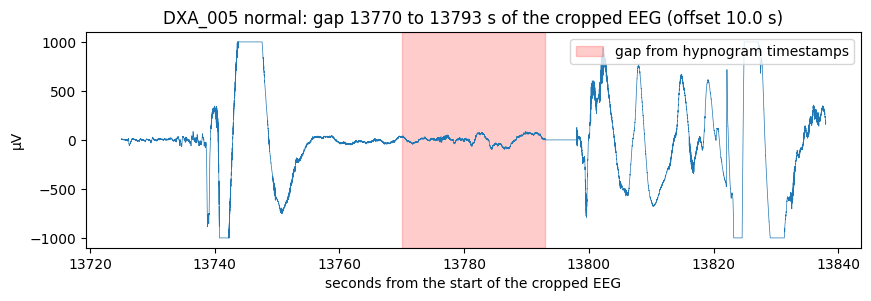

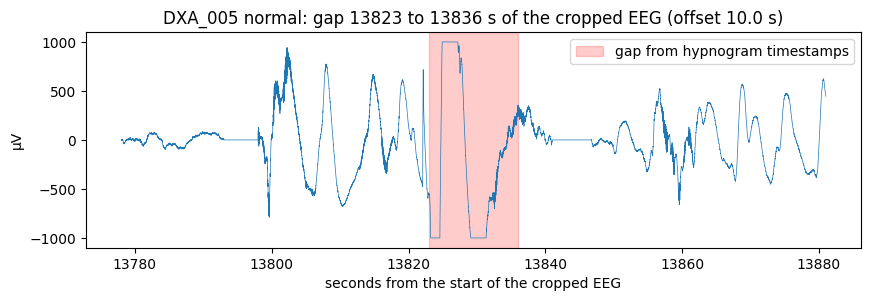

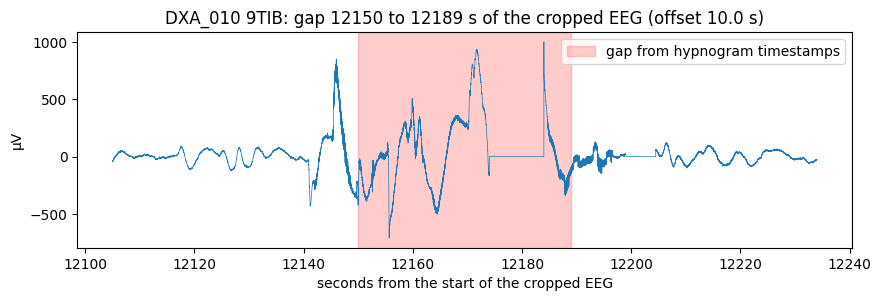

In [21]:
## CELL 19 | EEG around each gap (red band = gap predicted from the hypnogram timestamps)
def plot_gap(r, pad=45):
    raw = r.EDF_trim
    sf = raw.info["sfreq"]
    for g0, g1 in r.gaps:
        t0, t1 = max(g0 - pad, 0.0), min(g1 + pad, raw.n_times / sf)
        x = raw.get_data(start=int(t0 * sf), stop=int(t1 * sf), units="uV")[0]
        t = np.arange(len(x)) / sf + t0
        fig, ax = plt.subplots(figsize=(10, 2.8))
        ax.plot(t, x, lw=0.5)
        ax.axvspan(g0, g1, color="red", alpha=0.2, label="gap from hypnogram timestamps")
        ax.set_title(f"{r.subject_id} {r.condition}: gap {g0:.0f} to {g1:.0f} s of the cropped EEG (offset {r.offset_sec} s)")
        ax.set_xlabel("seconds from the start of the cropped EEG")
        ax.set_ylabel("µV")
        ax.legend(loc="upper right")
        plt.show()

for r in manifest_cleaned[manifest_cleaned["n_gaps"] > 0].itertuples():
    plot_gap(r)

### Sleep Profiler Scoring Key
**Primary stage classification from Sleep Profiler auto-scoring:**
- 0 = wake
- 1 = N1
- 2 = N2
- 3 = N3
- 4 = L2 (light N2)
- 5 = REM
- 6 = NOS (sleep not otherwise specified)
- 9 = INVALID
- 14 = NRH (Non-REM hypertonia)
- 33 = Atypical N3
- 55 = RSWA (REM sleep without atonia)

**YASA 5-Stage scoring key**
- -2 = 'unscored'
- -1 = artifact/movement
- 0 = wake
- 1 = NREM_1
- 2 = NREM_2
- 3 = NREM_3
- 4 = REM

In [22]:
## CELL 20 | Per-sample stage mask (hypnogram placed on the EEG by timestamp) and its check
def window_stage_ints(r):
    """YASA integer stage for each hypnogram epoch inside B-C (-2 = unscored/UNS)."""
    _, codes = load_hypno(r.hyp_path, window=(r.i0, r.i1))
    return codes.map(STAGE_MAP).map(STAGE_INT).to_numpy()

def hypno_to_samples_timed(stage_ints, el_win, tmin, n_samples, sf):
    """One stage value per EEG sample, placed by each epoch's start time. Time not covered by an epoch stays -2."""
    out = np.full(n_samples, -2, dtype=int)
    n = int(round(EPOCH_SEC * sf))
    for s, t in zip(stage_ints, el_win):
        a = int(round((t - tmin) * sf))
        if 0 <= a < n_samples:
            out[a:min(a + n, n_samples)] = s
    return out

chk = []
for r in manifest_cleaned.itertuples():
    ints = window_stage_ints(r)
    el_win = epoch_starts_edf(r.hyp_path)[r.i0:r.i1 + 1]
    sf, n = r.EDF_trim.info["sfreq"], r.EDF_trim.n_times
    up = hypno_to_samples_timed(ints, el_win, max(el_win[0], 0.0), n, sf)
    unscored_sec = float((up == -2).sum() / sf)
    expected_sec = int((ints == -2).sum()) * EPOCH_SEC + r.gap_total_sec    # UNS epochs + documented gaps
    chk.append({"subject_id": r.subject_id, "condition": r.condition,
                "n_uns_epochs": int((ints == -2).sum()), "n_gaps": r.n_gaps, "gap_total_sec": r.gap_total_sec,
                "unscored_sec": round(unscored_sec, 1), "expected_sec": round(expected_sec, 1),
                "diff_sec": round(unscored_sec - expected_sec, 2),
                "first_sample_stage": int(up[0]), "last_sample_stage": int(up[-1])})

placement_check = pd.DataFrame(chk)
placement_check["ok"] = placement_check["diff_sec"].abs() <= 1
print(f"{int(placement_check['ok'].sum())} of {len(placement_check)} nights: unscored time = UNS epochs + gaps")
display(placement_check)

20 of 20 nights: unscored time = UNS epochs + gaps


,subject_id,condition,n_uns_epochs,n_gaps,gap_total_sec,unscored_sec,expected_sec,diff_sec,first_sample_stage,last_sample_stage,ok
0,DXA_001,9TIB,0,0,0.0,0.0,0.0,0.0,0,0,True
1,DXA_001,normal,0,0,0.0,0.0,0.0,0.0,0,0,True
2,DXA_002,9TIB,7,0,0.0,210.0,210.0,0.0,0,0,True
3,DXA_002,normal,4,0,0.0,120.0,120.0,0.0,0,0,True
4,DXA_003,9TIB,0,0,0.0,0.0,0.0,0.0,0,0,True
5,DXA_003,normal,0,0,0.0,0.0,0.0,0.0,0,0,True
6,DXA_004,9TIB,0,0,0.0,0.0,0.0,0.0,0,0,True
7,DXA_004,normal,1,0,0.0,30.0,30.0,0.0,0,0,True
8,DXA_005,9TIB,3,0,0.0,90.0,90.0,0.0,0,0,True
9,DXA_005,normal,20,2,36.0,636.0,636.0,0.0,0,0,True
